# How DeiT-Tiny processes an image

Follow one synthetic RGB image through the same architecture used in all three training conditions.


In [1]:
%matplotlib inline
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import torch

from fairage.model import DeiTTiny

ROOT = Path.cwd()
while not (ROOT / "configs/baseline.yaml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open inside the project checkout")
    ROOT = ROOT.parent
OUT = ROOT / "results/simplified/vit_math"
SAVE_OUTPUTS = False
if SAVE_OUTPUTS:
    OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.manual_seed(4531)
model = DeiTTiny().cpu().eval()
plt.rcParams.update({"font.size": 11, "savefig.dpi": 300})
print("Custom nine-class parameters:", sum(p.numel() for p in model.parameters()))


Custom nine-class parameters: 5526153


## 2. Image patches

A 224 × 224 RGB image splits into 196 patches of 16 × 16 pixels. A convolution projects each patch’s 768 RGB values into 192 features.


Pixels: (1, 3, 224, 224) projection: (1, 192, 14, 14) patches: (1, 196, 192)


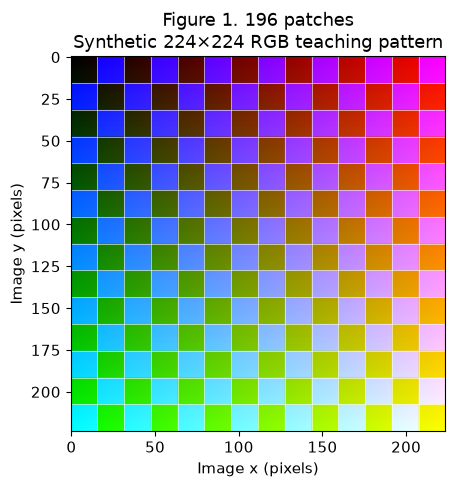

In [2]:
# Deterministic gradients/checkerboard: synthetic RGB, with no dataset record.
yy, xx = np.mgrid[:224, :224]
pixels = np.stack((xx * 255 // 223, yy * 255 // 223,
                   ((xx // 16 + yy // 16) % 2) * 255), axis=-1).astype(np.uint8)
example_target = 0  # Arbitrary class index for the backward-pass demonstration.
image = torch.from_numpy(pixels).permute(2, 0, 1).float().unsqueeze(0) / 255
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
image = (image - mean) / std
with torch.no_grad():
    projected = model.patch_embed(image)
    patches = projected.flatten(2).transpose(1, 2)
assert projected.shape == (1, 192, 14, 14) and patches.shape == (1, 196, 192)
print("Pixels:", tuple(image.shape), "projection:", tuple(projected.shape),
      "patches:", tuple(patches.shape))

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(pixels)
for edge in range(0, 225, 16):
    ax.axhline(edge - .5, color="white", linewidth=.4)
    ax.axvline(edge - .5, color="white", linewidth=.4)
ax.set(title="Figure 1. 196 patches\nSynthetic 224×224 RGB teaching pattern",
       xlabel="Image x (pixels)", ylabel="Image y (pixels)")
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUT / "fig_01_image_patches.png", bbox_inches="tight")
plt.show()


**Figure 1.** The synthetic image and its patch grid. Set `SAVE_OUTPUTS = True` to export the figures.

## 3. Position embeddings and the class token

Add a position embedding to each token. The extra class token brings the sequence to 197 tokens.


In [3]:
with torch.no_grad():
    cls = model.cls_token.expand(1, -1, -1)
    tokens = torch.cat((cls, patches), dim=1) + model.pos_embed
assert tokens.shape == (1, 197, 192)
print("197 tokens = 1 CLS + 196 patches; feature width =", tokens.shape[-1])


197 tokens = 1 CLS + 196 patches; feature width = 192


## 4. Three-head self-attention

Each head builds queries, keys, and values of shape 197 × 64.

\[\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(QK^T/\sqrt{64})V.\]

PyTorch’s attention operation applies the scale internally.


Q/K/V: (1, 3, 197, 64) attention weights: (1, 3, 197, 197)


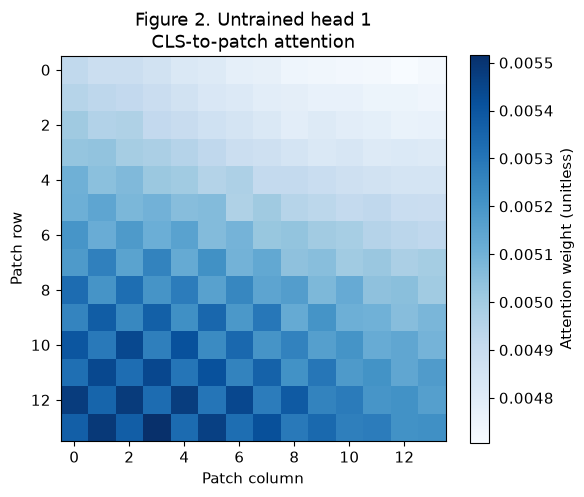

In [4]:
with torch.no_grad():
    normalized = model.blocks[0].norm1(tokens)
    qkv = model.blocks[0].attn.qkv(normalized).reshape(1, 197, 3, 3, 64)
    q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
    attention = (q @ k.transpose(-2, -1) / math.sqrt(64)).softmax(dim=-1)
    manual = attention @ v
    optimized = torch.nn.functional.scaled_dot_product_attention(q, k, v, dropout_p=0.0)
torch.testing.assert_close(manual, optimized, atol=1e-6, rtol=1e-5)
print("Q/K/V:", tuple(q.shape), "attention weights:", tuple(attention.shape))

fig, ax = plt.subplots(figsize=(6, 5))
heat = ax.imshow(attention[0, 0, 0, 1:].reshape(14, 14).numpy(), cmap="Blues")
ax.set(title="Figure 2. Untrained head 1\nCLS-to-patch attention",
       xlabel="Patch column", ylabel="Patch row")
ax.set_xticks(range(0, 14, 2))
ax.set_yticks(range(0, 14, 2))
fig.colorbar(heat, ax=ax, label="Attention weight (unitless)")
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUT / "fig_02_cls_attention.png", bbox_inches="tight")
plt.show()


**Figure 2.** Attention from the class token to image patches in the first head of the first block. The plot omits the class token’s weight. These are untrained weights on a synthetic image.

## 5. Transformer blocks and age logits

\[u=x+\operatorname{Attention}(\operatorname{LN}(x)),\qquad y=u+\operatorname{MLP}(\operatorname{LN}(u)).\]

After 12 blocks and a final LayerNorm, the classifier maps the class token to nine apparent-age logits.


In [5]:
with torch.no_grad():
    block_output = model.blocks[0](tokens)
    features = model.forward_features(image)
    logits = model(image)
assert block_output.shape == features.shape == (1, 197, 192)
assert logits.shape == (1, 9)
shapes = pd.DataFrame([
    ("RGB input", str(tuple(image.shape))),
    ("patch tokens", str(tuple(patches.shape))),
    ("CLS + positions", str(tuple(tokens.shape))),
    ("12 blocks + norm", str(tuple(features.shape))),
    ("age logits", str(tuple(logits.shape))),
], columns=["operation", "shape"])
if SAVE_OUTPUTS:
    shapes.to_csv(OUT / "tensor_shapes.csv", index=False)
display(shapes)
print("Synthetic example; arbitrary target index:", example_target)


,operation,shape
0,RGB input,"(1, 3, 224, 224)"
1,patch tokens,"(1, 196, 192)"
2,CLS + positions,"(1, 197, 192)"
3,12 blocks + norm,"(1, 197, 192)"
4,age logits,"(1, 9)"


Synthetic example; arbitrary target index: 0


## CPU gradient check

Run one backward pass to check that gradients flow through the model.


In [6]:
model.train()
model.zero_grad(set_to_none=True)
logits = model(image)
loss = torch.nn.functional.cross_entropy(logits, torch.tensor([example_target]))
loss.backward()
print("CPU logits:", tuple(logits.shape))
print("All parameter gradients finite:",
      all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters()))


CPU logits: (1, 9)
All parameter gradients finite: True
